# AR(p) Process and Forward Sliding-Window Embeddings

This notebook:

1. generates an autoregressive process of order $p$,
2. plots the resulting time series, and
3. constructs forward sliding-window embeddings and plots the point clouds for $k=2$ and $k=3$,
4. splits the process chronologically into training and test parts, and
5. estimates completion matrices $\hat A_k$ on the training part and lifts the test clouds to the common ambient space $\mathbb{R}^{k_{\max}}$.

The AR($p$) model is

$$x_t = c + \phi_1 x_{t-1} + \cdots + \phi_p x_{t-p} + \varepsilon_t,$$

where $\varepsilon_t \sim \mathcal{N}(0, \sigma^2)$. The forward embedding of dimension $k$ is

$$\mathbf{x}_t^{(k)} = (x_t, x_{t+1}, \ldots, x_{t+k-1}).$$

In [53]:
import math
import numpy as np
import matplotlib.pyplot as plt
import gudhi
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import coo_matrix

plt.style.use("seaborn-v0_8-whitegrid")

## Functions

In [54]:
def generate_ar_process(phi, n=1_000, sigma=1.0, intercept=0.0,
                        burn_in=500, initial_values=None, seed=None):
    """Generate an AR(p) process.

    Parameters
    ----------
    phi : array-like
        AR coefficients [phi_1, ..., phi_p].
    n : int
        Number of observations returned after burn-in.
    sigma : float
        Standard deviation of the Gaussian innovations.
    intercept : float
        Constant term in the AR equation.
    burn_in : int
        Number of initial simulated observations discarded.
    initial_values : array-like or None
        Optional p starting values. Zeros are used by default.
    seed : int or None
        Random seed for reproducibility.

    Returns
    -------
    np.ndarray
        Simulated observations of shape (n,).
    """
    phi = np.asarray(phi, dtype=float)
    if phi.ndim != 1 or phi.size == 0:
        raise ValueError("phi must be a non-empty one-dimensional sequence.")
    if n <= 0 or burn_in < 0:
        raise ValueError("n must be positive and burn_in must be non-negative.")
    if sigma < 0:
        raise ValueError("sigma must be non-negative.")

    p = phi.size
    total = n + burn_in
    x = np.zeros(total + p)

    if initial_values is not None:
        initial_values = np.asarray(initial_values, dtype=float)
        if initial_values.shape != (p,):
            raise ValueError(f"initial_values must contain exactly {p} values.")
        x[:p] = initial_values

    rng = np.random.default_rng(seed)
    innovations = rng.normal(loc=0.0, scale=sigma, size=total)

    for t in range(p, total + p):
        past = x[t - p:t][::-1]  # [x_(t-1), ..., x_(t-p)]
        x[t] = intercept + phi @ past + innovations[t - p]

    return x[p + burn_in:p + burn_in + n]


def forward_sliding_window_embedding(x, k):
    """Return rows (x_t, x_(t+1), ..., x_(t+k-1))."""
    x = np.asarray(x, dtype=float)
    if x.ndim != 1:
        raise ValueError("x must be one-dimensional.")
    if not isinstance(k, (int, np.integer)) or not 1 <= k <= x.size:
        raise ValueError("k must be an integer between 1 and len(x).")
    return np.lib.stride_tricks.sliding_window_view(x, window_shape=k).copy()


def fit_completion_matrices(x_train, k_max):
    """Estimate A_hat[k] from complete k_max-windows in the training data.

    For each k, A_hat[k] minimizes ||Z_k - Y_k A.T||_F^2, where Y_k
    contains the first k entries and Z_k the remaining k_max-k entries
    of each complete forward window. No intercept is included, matching
    the linear dimension lift used in the thesis.
    """
    full_windows = forward_sliding_window_embedding(x_train, k_max)
    A_hat = {}

    for k in range(1, k_max + 1):
        Y_k = full_windows[:, :k]
        Z_k = full_windows[:, k:]

        if k == k_max:
            A_hat[k] = np.empty((0, k_max))
        else:
            # np.linalg.lstsq is numerically safer than forming an inverse.
            coefficients, *_ = np.linalg.lstsq(Y_k, Z_k, rcond=None)
            A_hat[k] = coefficients.T

    return A_hat


def lift_windows(x, k, k_max, A_k):
    """Lift k-dimensional forward windows to R^k_max using a fitted A_k."""
    if not 1 <= k <= k_max:
        raise ValueError("k must lie between 1 and k_max.")
    if len(x) < k_max:
        raise ValueError("x must contain at least k_max observations.")

    # Use the same start times for every k: t=0,...,len(x)-k_max.
    Y_k = forward_sliding_window_embedding(x, k)[:len(x) - k_max + 1]
    predicted_tail = Y_k @ A_k.T
    return np.hstack((Y_k, predicted_tail))


def prediction_error_vectors(x, k, k_max, A_k):
    """Return z_hat_t^(k) - z_t^(k) for complete k_max-windows."""
    full_windows = forward_sliding_window_embedding(x, k_max)
    if k == k_max:
        return np.zeros((len(full_windows), 0))

    Y_k = full_windows[:, :k]
    true_tail = full_windows[:, k:]
    predicted_tail = Y_k @ A_k.T
    return predicted_tail - true_tail


def similar_error_complex(errors, k, tau):
    """Construct L_k as a GUDHI flag complex using similar errors.

    Candidate temporal edges {s,t} satisfy 1 <= |s-t| <= k-1. An edge
    is retained exactly when both endpoint error norms and the norm of
    their error difference are at most tau.
    """
    errors = np.asarray(errors, dtype=float)
    n_vertices = len(errors)
    simplex_tree = gudhi.SimplexTree()

    # All time indices remain vertices, including isolated ones.
    for vertex in range(n_vertices):
        simplex_tree.insert([vertex], filtration=0.0)

    error_norms = np.linalg.norm(errors, axis=1)
    retained_edges = []

    for lag in range(1, k):
        for s in range(n_vertices - lag):
            t = s + lag
            difference_norm = np.linalg.norm(errors[s] - errors[t])
            if (error_norms[s] <= tau and
                    error_norms[t] <= tau and
                    difference_norm <= tau):
                simplex_tree.insert([s, t], filtration=0.0)
                retained_edges.append((s, t))

    # L_k is the flag (clique) complex. Two-simplices are sufficient for
    # correct beta_0 and beta_1; k=2 has a one-dimensional base complex.
    if k >= 3:
        simplex_tree.expansion(max_dimension=2)

    simplex_tree.compute_persistence(homology_coeff_field=2,
                                     persistence_dim_max=True)
    betti = simplex_tree.betti_numbers()
    beta_0 = betti[0] if len(betti) > 0 else 0
    beta_1 = betti[1] if len(betti) > 1 else 0

    return simplex_tree, retained_edges, beta_0, beta_1

## Choose the AR(p) parameters

Change `phi` to set both the order $p$ and its coefficients. For example, `phi = [0.7]` gives an AR(1), while the values below give an AR(2). A burn-in period reduces the influence of the zero initialization.

In [55]:
# Model and simulation settings
phi = [0.75, -0.25]  # [phi_1, ..., phi_p]
n = 1_000
sigma = 0.7
intercept = 0.0
burn_in = 500
seed = 42
train_fraction = 0.7
k_max = 5

x = generate_ar_process(
    phi=phi,
    n=n,
    sigma=sigma,
    intercept=intercept,
    burn_in=burn_in,
    seed=seed,
)

split_index = int(train_fraction * len(x))
x_train = x[:split_index]
x_test = x[split_index:]

print(f"Generated an AR({len(phi)}) process with {len(x)} observations.")
print(f"Training observations: {len(x_train)}")
print(f"Test observations: {len(x_test)}")
print(f"Sample mean: {x.mean():.3f}")
print(f"Sample standard deviation: {x.std(ddof=1):.3f}")

Generated an AR(2) process with 1000 observations.
Training observations: 700
Test observations: 300
Sample mean: -0.035
Sample standard deviation: 0.954


## Plot the AR(p) process

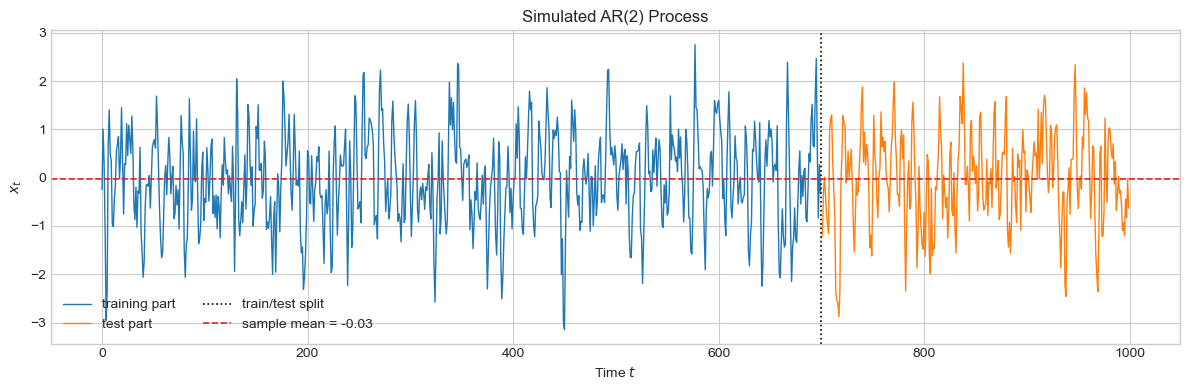

In [56]:
fig, ax = plt.subplots(figsize=(12, 4))
time = np.arange(n)
ax.plot(time[:split_index], x_train, color="tab:blue", linewidth=1.0,
        label="training part")
ax.plot(time[split_index:], x_test, color="tab:orange", linewidth=1.0,
        label="test part")
ax.axvline(split_index - 0.5, color="black", linestyle=":", linewidth=1.2,
           label="train/test split")
ax.axhline(x.mean(), color="tab:red", linestyle="--", linewidth=1.2,
           label=f"sample mean = {x.mean():.2f}")
ax.set(
    title=f"Simulated AR({len(phi)}) Process",
    xlabel="Time $t$",
    ylabel="$x_t$",
)
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

## Forward sliding-window embeddings

Each row of `cloud_k2` is $(x_t, x_{t+1})$, and each row of `cloud_k3` is $(x_t, x_{t+1}, x_{t+2})$.

In [57]:
cloud_k2 = forward_sliding_window_embedding(x, k=2)
cloud_k3 = forward_sliding_window_embedding(x, k=3)

print("k=2 cloud shape:", cloud_k2.shape)
print("k=3 cloud shape:", cloud_k3.shape)

k=2 cloud shape: (999, 2)
k=3 cloud shape: (998, 3)


### Point cloud for k = 2

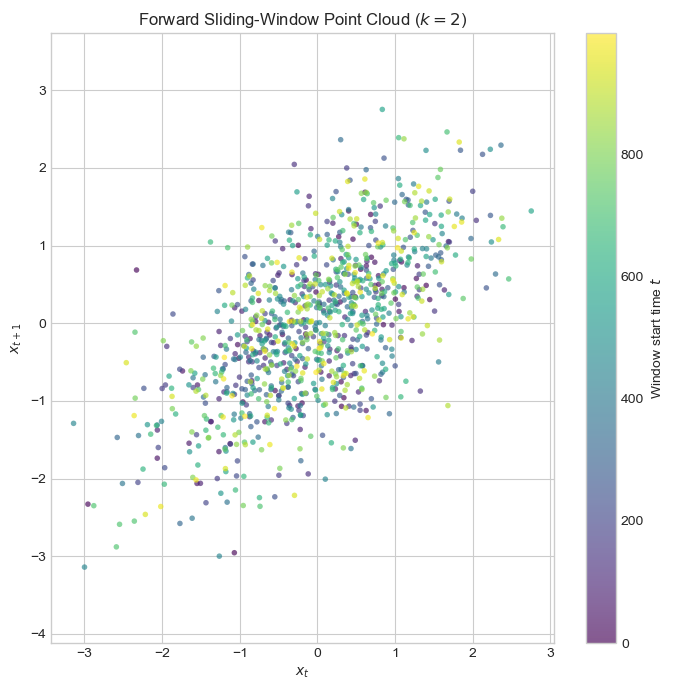

In [58]:
fig, ax = plt.subplots(figsize=(7, 7))
scatter = ax.scatter(
    cloud_k2[:, 0],
    cloud_k2[:, 1],
    c=np.arange(len(cloud_k2)),
    cmap="viridis",
    s=16,
    alpha=0.65,
    edgecolors="none",
)
ax.set(
    title="Forward Sliding-Window Point Cloud ($k=2$)",
    xlabel="$x_t$",
    ylabel="$x_{t+1}$",
)
ax.set_aspect("equal", adjustable="datalim")
fig.colorbar(scatter, ax=ax, label="Window start time $t$")
fig.tight_layout()
plt.show()

### Point cloud for k = 3

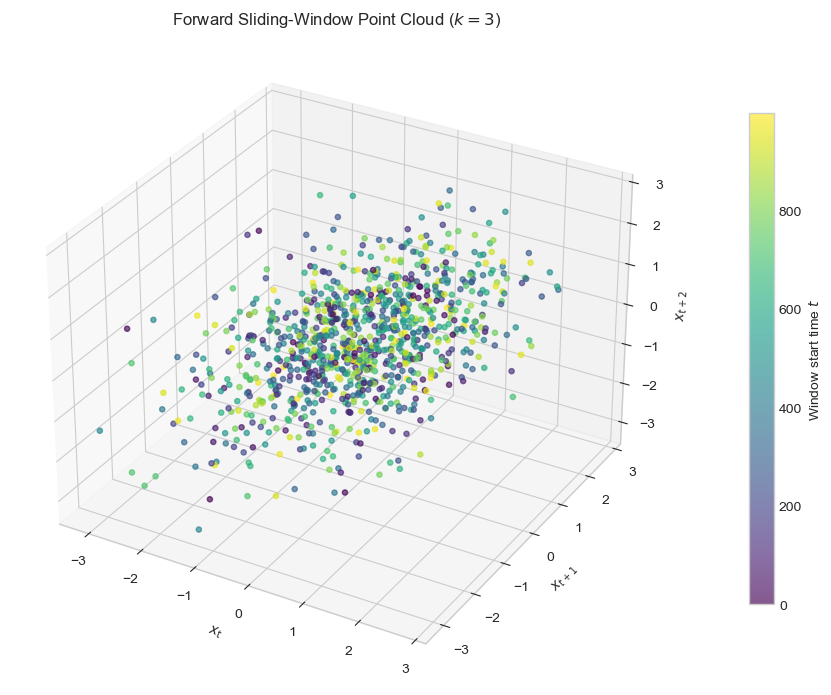

In [59]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(
    cloud_k3[:, 0],
    cloud_k3[:, 1],
    cloud_k3[:, 2],
    c=np.arange(len(cloud_k3)),
    cmap="viridis",
    s=14,
    alpha=0.65,
    depthshade=True,
)
ax.set(
    title="Forward Sliding-Window Point Cloud ($k=3$)",
    xlabel="$x_t$",
    ylabel="$x_{t+1}$",
    zlabel="$x_{t+2}$",
)
fig.colorbar(scatter, ax=ax, pad=0.1, shrink=0.75,
             label="Window start time $t$")
fig.tight_layout()
plt.show()

## Train the completion matrices $\hat A_k$

For each $k=1,\ldots,k_{\max}$, every complete training window of length $k_{\max}$ is split into

$$Y_t^{(k)}=(x_t,\ldots,x_{t+k-1})^T$$

and its missing future tail

$$z_t^{(k)}=(x_{t+k},\ldots,x_{t+k_{\max}-1})^T.$$

The matrix $\hat A_k\in\mathbb{R}^{(k_{\max}-k)\times k}$ is estimated only from the training part by minimizing

$$\sum_t\left\|z_t^{(k)}-A Y_t^{(k)}\right\|_2^2.$$

For $k=k_{\max}$, no coordinates are missing, so $\hat A_{k_{\max}}$ is an empty completion matrix.

In [60]:
A_hat = fit_completion_matrices(x_train, k_max=k_max)

for k, A_k in A_hat.items():
    print(f"A_hat[{k}] shape = {A_k.shape}")
    if A_k.size:
        print(np.round(A_k, 3))
    else:
        print("No completion is needed for k = k_max.")
    print()

A_hat[1] shape = (4, 1)
[[ 0.636]
 [ 0.223]
 [ 0.018]
 [-0.046]]

A_hat[2] shape = (3, 2)
[[-0.304  0.829]
 [-0.209  0.356]
 [-0.096  0.078]]

A_hat[3] shape = (2, 3)
[[ 0.047 -0.341  0.841]
 [ 0.015 -0.224  0.365]]

A_hat[4] shape = (1, 4)
[[-0.024  0.061 -0.339  0.838]]

A_hat[5] shape = (0, 5)
No completion is needed for k = k_max.



## Lift the test point clouds to $\mathbb{R}^{k_{\max}}$

The fitted matrices are now frozen. For each $k$, the test windows are lifted according to

$$p_t^{(k)}=\begin{pmatrix}Y_t^{(k)}\\ \hat A_kY_t^{(k)}\end{pmatrix}\in\mathbb{R}^{k_{\max}}.$$

Only windows lying completely within the test segment are used. Every lifted cloud therefore has the same number of points and the same ambient dimension.

In [61]:
lifted_test_clouds = {
    k: lift_windows(x_test, k=k, k_max=k_max, A_k=A_hat[k])
    for k in range(1, k_max + 1)
}

for k, cloud in lifted_test_clouds.items():
    print(f"Lifted test cloud for k={k}: {cloud.shape}")

assert all(cloud.shape[1] == k_max for cloud in lifted_test_clouds.values())
assert len({cloud.shape[0] for cloud in lifted_test_clouds.values()}) == 1

Lifted test cloud for k=1: (296, 5)
Lifted test cloud for k=2: (296, 5)
Lifted test cloud for k=3: (296, 5)
Lifted test cloud for k=4: (296, 5)
Lifted test cloud for k=5: (296, 5)


### Out-of-sample completion error

The following diagnostic compares the predicted coordinates with the actual unseen coordinates in the complete test windows. For $k=k_{\max}$ there is no prediction error because no completion is required.

In [62]:
true_test_windows = forward_sliding_window_embedding(x_test, k_max)
test_rmse = {}

for k in range(1, k_max + 1):
    if k == k_max:
        test_rmse[k] = 0.0
    else:
        predicted_tail = lifted_test_clouds[k][:, k:]
        true_tail = true_test_windows[:, k:]
        test_rmse[k] = np.sqrt(np.mean((true_tail - predicted_tail) ** 2))

for k, rmse in test_rmse.items():
    print(f"k={k}: test completion RMSE = {rmse:.4f}")

k=1: test completion RMSE = 0.9079
k=2: test completion RMSE = 0.8827
k=3: test completion RMSE = 0.8393
k=4: test completion RMSE = 0.7436
k=5: test completion RMSE = 0.0000


### Visualize the lifted test clouds

The lifted clouds live in $\mathbb{R}^5$, which cannot be displayed directly. The plots below show their first three ambient coordinates. The full five-dimensional arrays remain available in `lifted_test_clouds`.

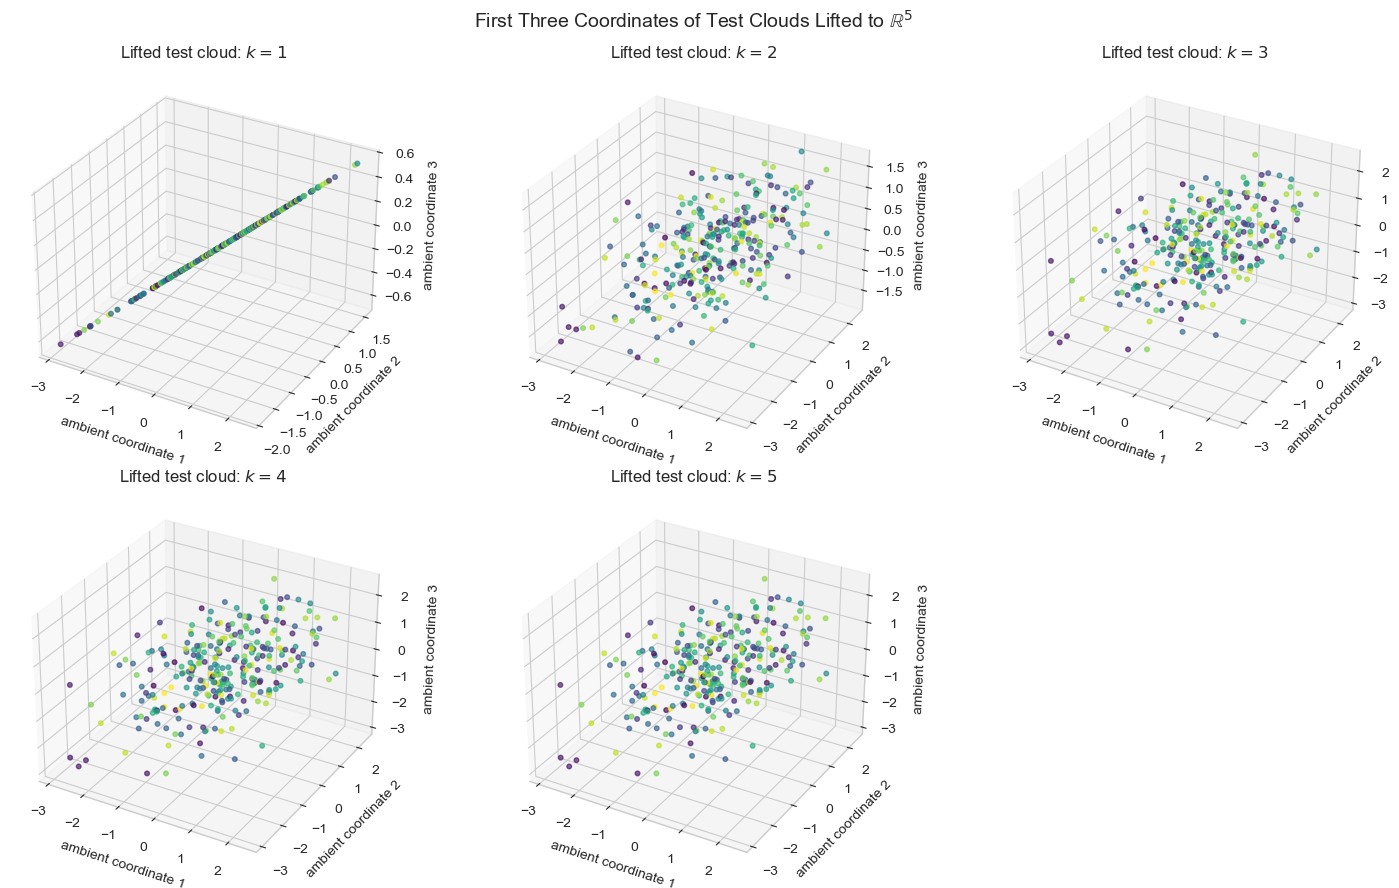

In [63]:
fig = plt.figure(figsize=(15, 9))

for k in range(1, k_max + 1):
    ax = fig.add_subplot(2, 3, k, projection="3d")
    cloud = lifted_test_clouds[k]
    ax.scatter(
        cloud[:, 0], cloud[:, 1], cloud[:, 2],
        c=np.arange(len(cloud)), cmap="viridis",
        s=11, alpha=0.65, depthshade=True,
    )
    ax.set_title(f"Lifted test cloud: $k={k}$")
    ax.set_xlabel("ambient coordinate 1")
    ax.set_ylabel("ambient coordinate 2")
    ax.set_zlabel("ambient coordinate 3")

fig.suptitle(
    f"First Three Coordinates of Test Clouds Lifted to $\\mathbb{{R}}^{k_max}$",
    fontsize=14,
)
fig.tight_layout()
plt.show()

## Data-dependent simplicial complexes from similar prediction errors

For each scale $k$, let

$$e_t^{(k)}=\hat z_t^{(k)}-z_t^{(k)}$$

be the out-of-sample completion-error vector. The temporal graph $G_k$ contains a candidate edge $\{s,t\}$ whenever

$$1\leq |s-t|\leq k-1.$$

Following the similar-error rule, the candidate edge is retained when

$$\|e_s^{(k)}\|_2\leq\tau_k,\qquad
\|e_t^{(k)}\|_2\leq\tau_k,\qquad
\|e_s^{(k)}-e_t^{(k)}\|_2\leq\tau_k.$$

The data-dependent complex is the flag complex $L_k=\operatorname{Flag}(H_k)$ of the retained graph. GUDHI's `SimplexTree` stores the vertices and edges and expands all cliques through dimension two, which is sufficient to calculate $\beta_0$ and $\beta_1$.

The thesis leaves $\tau$ as a tuning parameter. Here, `tau_quantile = 0.5` chooses $\tau_k$ as the median test-error norm at each scale. You can change this value between 0 and 1. For $k=k_{\max}$, the completion error is identically zero and $\tau_{k_{\max}}=0$.

In [64]:
tau_quantile = 0.5

if not 0 <= tau_quantile <= 1:
    raise ValueError("tau_quantile must lie between 0 and 1.")

test_error_vectors = {
    k: prediction_error_vectors(x_test, k, k_max, A_hat[k])
    for k in range(1, k_max + 1)
}

tau_by_k = {
    k: float(np.quantile(np.linalg.norm(errors, axis=1), tau_quantile))
    for k, errors in test_error_vectors.items()
}

complexes_L = {}
retained_edges_by_k = {}
betti_by_k = {}

for k in range(1, k_max + 1):
    L_k, retained_edges, beta_0, beta_1 = similar_error_complex(
        errors=test_error_vectors[k],
        k=k,
        tau=tau_by_k[k],
    )
    complexes_L[k] = L_k
    retained_edges_by_k[k] = retained_edges
    betti_by_k[k] = (beta_0, beta_1)

    n_vertices = L_k.num_vertices()
    n_simplices = L_k.num_simplices()
    print(
        f"L_{k}: tau={tau_by_k[k]:.4f}, vertices={n_vertices}, "
        f"edges={len(retained_edges)}, simplices={n_simplices}, "
        f"beta_0={beta_0}, beta_1={beta_1}"
    )

L_1: tau=1.5056, vertices=296, edges=0, simplices=296, beta_0=296, beta_1=0
L_2: tau=1.1990, vertices=296, edges=59, simplices=355, beta_0=237, beta_1=0
L_3: tau=0.9034, vertices=296, edges=101, simplices=418, beta_0=217, beta_1=1
L_4: tau=0.4839, vertices=296, edges=154, simplices=504, beta_0=190, beta_1=1
L_5: tau=0.0000, vertices=296, edges=1174, simplices=3226, beta_0=1, beta_1=0


The dictionary `complexes_L` is the requested sequence $(L_1,\ldots,L_{k_{\max}})$. In particular, `complexes_L[k]` is a GUDHI `SimplexTree`.

## Betti numbers versus embedding scale

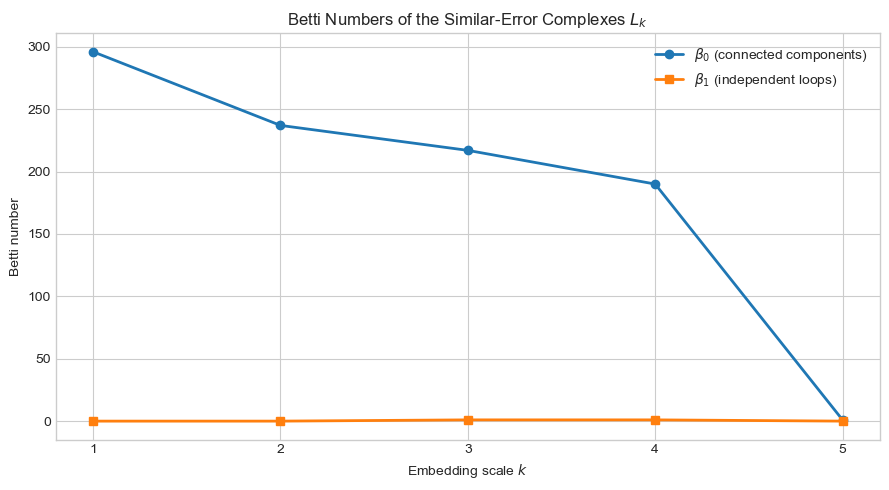

In [65]:
k_values = np.arange(1, k_max + 1)
beta_0_values = np.array([betti_by_k[k][0] for k in k_values])
beta_1_values = np.array([betti_by_k[k][1] for k in k_values])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_values, beta_0_values, marker="o", linewidth=2,
        label=r"$\beta_0$ (connected components)")
ax.plot(k_values, beta_1_values, marker="s", linewidth=2,
        label=r"$\beta_1$ (independent loops)")
ax.set(
    title="Betti Numbers of the Similar-Error Complexes $L_k$",
    xlabel="Embedding scale $k$",
    ylabel="Betti number",
    xticks=k_values,
)
ax.legend()
fig.tight_layout()
plt.show()

### Retained-edge diagnostic

This additional plot shows how strongly the error rule sparsifies the temporal graph at each scale.

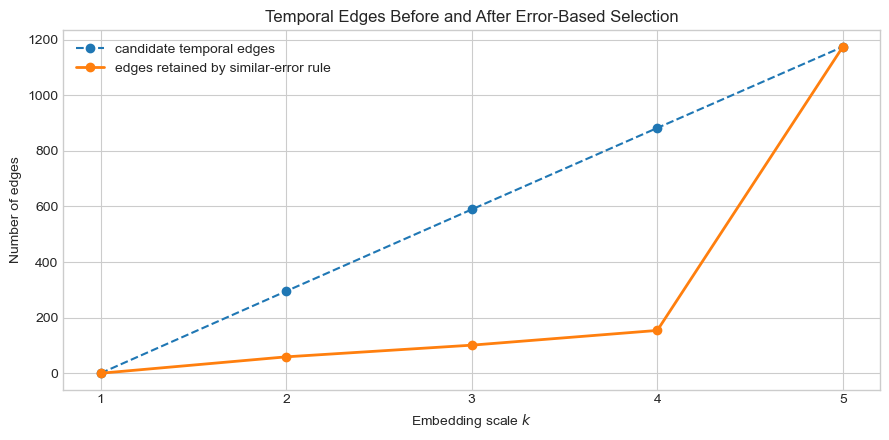

In [66]:
n_test_windows = len(true_test_windows)
candidate_edge_counts = np.array([
    sum(n_test_windows - lag for lag in range(1, k))
    for k in k_values
])
retained_edge_counts = np.array([
    len(retained_edges_by_k[k]) for k in k_values
])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(k_values, candidate_edge_counts, marker="o", linestyle="--",
        label="candidate temporal edges")
ax.plot(k_values, retained_edge_counts, marker="o", linewidth=2,
        label="edges retained by similar-error rule")
ax.set(
    title="Temporal Edges Before and After Error-Based Selection",
    xlabel="Embedding scale $k$",
    ylabel="Number of edges",
    xticks=k_values,
)
ax.legend()
fig.tight_layout()
plt.show()

## Functionals presented in the thesis

The thesis presents the following computable scalar functionals or families for simplicial complexes:

- the face numbers $f_0,f_1,f_2$ from the $f$-vector;
- the Betti numbers and total Betti number;
- the Euler characteristic $\chi$;
- the vertex-cover number $\tau$ and matching number $\nu$ of the top-dimensional facets;
- chain counts $c_r$;
- degree-type counts $\Delta_t$;
- geometric volume; and
- polynomial-type products $f_{\mathrm{Top}}f_{\mathrm{Comb}}$, with $\beta_0f_1$ given explicitly as an example.

Lusternik–Schnirelmann category is named in the thesis but no computational prescription is developed there, so it is not evaluated below. The intrinsic volumes $V_j$ occur in the separate zonotope construction for uniformly distributed innovations; they do not apply directly to the present Gaussian similar-error complexes.

The vertical dashed line in each plot marks the known simulation order $p$; it is used only for evaluation, never for constructing the complexes.

In [67]:
def simplices_by_dimension(simplex_tree, max_dimension=2):
    """Return the simplices of a GUDHI complex grouped by dimension."""
    grouped = {dimension: [] for dimension in range(max_dimension + 1)}
    for simplex, _ in simplex_tree.get_filtration():
        dimension = len(simplex) - 1
        if dimension <= max_dimension:
            grouped[dimension].append(tuple(sorted(simplex)))
    return grouped


def top_dimensional_facets(simplices):
    """Use the thesis convention: facets are simplices of dimension dim(K)."""
    nonempty_dimensions = [d for d, values in simplices.items() if values]
    dimension = max(nonempty_dimensions)
    return simplices[dimension], dimension


def vertex_cover_and_matching_numbers(facets, n_vertices):
    """Compute facet cover/matching, with deterministic fallbacks if MILP times out."""
    if not facets:
        return 0, 0

    # Vertex cover: choose the fewest vertices meeting every top-dimensional facet.
    cover_rows, cover_cols = [], []
    for row, facet in enumerate(facets):
        for vertex in facet:
            cover_rows.append(row)
            cover_cols.append(vertex)
    cover_matrix = coo_matrix(
        (np.ones(len(cover_rows)), (cover_rows, cover_cols)),
        shape=(len(facets), n_vertices),
    ).tocsr()
    cover_result = milp(
        c=np.ones(n_vertices),
        integrality=np.ones(n_vertices),
        bounds=Bounds(0, 1),
        constraints=LinearConstraint(cover_matrix, 1, np.inf),
        options={"time_limit": 3},
    )

    # Matching: choose the largest collection of pairwise disjoint facets.
    match_rows, match_cols = [], []
    for column, facet in enumerate(facets):
        for vertex in facet:
            match_rows.append(vertex)
            match_cols.append(column)
    match_matrix = coo_matrix(
        (np.ones(len(match_rows)), (match_rows, match_cols)),
        shape=(n_vertices, len(facets)),
    ).tocsr()
    match_result = milp(
        c=-np.ones(len(facets)),
        integrality=np.ones(len(facets)),
        bounds=Bounds(0, 1),
        constraints=LinearConstraint(match_matrix, 0, 1),
        options={"time_limit": 3},
    )

    cover_exact = cover_result.success
    matching_exact = match_result.success

    if cover_exact:
        cover_number = int(round(cover_result.fun))
    else:
        # Greedy feasible cover: repeatedly choose the vertex meeting most
        # currently uncovered facets. This is an upper bound on tau.
        uncovered = set(range(len(facets)))
        incidence = [set() for _ in range(n_vertices)]
        for facet_index, facet in enumerate(facets):
            for vertex in facet:
                incidence[vertex].add(facet_index)
        cover_number = 0
        while uncovered:
            vertex = max(range(n_vertices), key=lambda v: len(incidence[v] & uncovered))
            uncovered -= incidence[vertex]
            cover_number += 1

    if matching_exact:
        matching_number = int(round(-match_result.fun))
    else:
        # Greedy feasible matching: prefer facets with fewer conflicts.
        facet_sets = [set(facet) for facet in facets]
        conflict_counts = [
            sum(bool(facet & other) for other in facet_sets) for facet in facet_sets
        ]
        used_vertices = set()
        matching_number = 0
        for index in np.argsort(conflict_counts):
            if facet_sets[index].isdisjoint(used_vertices):
                used_vertices.update(facet_sets[index])
                matching_number += 1

    return cover_number, matching_number, cover_exact, matching_exact


def chain_count(simplices, length):
    """Count strict inclusion chains sigma_0 subset ... subset sigma_length."""
    all_simplices = [frozenset(s) for values in simplices.values() for s in values]
    counts = np.ones(len(all_simplices), dtype=np.int64)
    for _ in range(length):
        next_counts = np.zeros_like(counts)
        for j, upper in enumerate(all_simplices):
            next_counts[j] = sum(
                counts[i] for i, lower in enumerate(all_simplices)
                if len(lower) < len(upper) and lower < upper
            )
        counts = next_counts
    return int(counts.sum())


def degree_type_count(simplices, target_dimension):
    """Compute Delta_t(K)=max_tau # {t-simplices containing tau}."""
    target_simplices = [frozenset(s) for s in simplices[target_dimension]]
    if not target_simplices:
        return 0
    all_simplices = [frozenset(s) for values in simplices.values() for s in values]
    return max(sum(tau <= sigma for sigma in target_simplices) for tau in all_simplices)


def geometric_complex_volume(simplices, coordinates):
    """Sum Gram-determinant volumes of the top-dimensional simplices."""
    facets, dimension = top_dimensional_facets(simplices)
    if dimension == 0:
        return float(len(facets))

    total = 0.0
    for facet in facets:
        points = coordinates[list(facet)]
        edge_matrix = (points[1:] - points[0]).T
        gram = edge_matrix.T @ edge_matrix
        total += np.sqrt(max(np.linalg.det(gram), 0.0)) / math.factorial(dimension)
    return float(total)

In [68]:
thesis_functionals = {
    r"$f_0$ (vertices)": [],
    r"$f_1$ (edges)": [],
    r"$f_2$ (triangles)": [],
    r"$\beta_0$": [],
    r"$\beta_1$": [],
    r"$\sum_j\beta_j$": [],
    r"$\chi$": [],
    r"$\tau$ (facet vertex cover)": [],
    r"$\nu$ (facet matching)": [],
    r"$c_1$": [],
    r"$c_2$": [],
    r"$\Delta_0$": [],
    r"$\Delta_1$": [],
    r"$\Delta_2$": [],
    r"$\operatorname{Vol}(L_k)$": [],
    r"$\beta_0 f_1$": [],
}

facet_optimization_exact = {}

for k in k_values:
    simplices = simplices_by_dimension(complexes_L[k], max_dimension=2)
    f0, f1, f2 = (len(simplices[d]) for d in range(3))
    beta0, beta1 = betti_by_k[k]
    facets, _ = top_dimensional_facets(simplices)
    vertex_cover, matching, cover_exact, matching_exact = (
        vertex_cover_and_matching_numbers(facets, f0)
    )
    facet_optimization_exact[k] = {
        "vertex_cover": cover_exact,
        "matching": matching_exact,
    }

    values = {
        r"$f_0$ (vertices)": f0,
        r"$f_1$ (edges)": f1,
        r"$f_2$ (triangles)": f2,
        r"$\beta_0$": beta0,
        r"$\beta_1$": beta1,
        r"$\sum_j\beta_j$": beta0 + beta1,
        r"$\chi$": f0 - f1 + f2,
        r"$\tau$ (facet vertex cover)": vertex_cover,
        r"$\nu$ (facet matching)": matching,
        r"$c_1$": chain_count(simplices, length=1),
        r"$c_2$": chain_count(simplices, length=2),
        r"$\Delta_0$": degree_type_count(simplices, 0),
        r"$\Delta_1$": degree_type_count(simplices, 1),
        r"$\Delta_2$": degree_type_count(simplices, 2),
        r"$\operatorname{Vol}(L_k)$": geometric_complex_volume(
            simplices, lifted_test_clouds[k]
        ),
        r"$\beta_0 f_1$": beta0 * f1,
    }
    for name, value in values.items():
        thesis_functionals[name].append(float(value))

thesis_functionals = {
    name: np.asarray(values) for name, values in thesis_functionals.items()
}

approximate_scales = {
    problem: [k for k, status in facet_optimization_exact.items() if not status[problem]]
    for problem in ("vertex_cover", "matching")
}
print("Facet optimization fallback scales:", approximate_scales)
print("Maximizers of the thesis-defined functionals:")
for name, values in thesis_functionals.items():
    maximizing_k = k_values[np.flatnonzero(values == values.max())]
    print(f"{name:35s} -> k = {maximizing_k.tolist()}")

Facet optimization fallback scales: {'vertex_cover': [5], 'matching': [5]}
Maximizers of the thesis-defined functionals:
$f_0$ (vertices)                    -> k = [1, 2, 3, 4, 5]
$f_1$ (edges)                       -> k = [5]
$f_2$ (triangles)                   -> k = [5]
$\beta_0$                           -> k = [1]
$\beta_1$                           -> k = [3, 4]
$\sum_j\beta_j$                     -> k = [1]
$\chi$                              -> k = [5]
$\tau$ (facet vertex cover)         -> k = [1]
$\nu$ (facet matching)              -> k = [1]
$c_1$                               -> k = [5]
$c_2$                               -> k = [5]
$\Delta_0$                          -> k = [1, 2, 3, 4, 5]
$\Delta_1$                          -> k = [5]
$\Delta_2$                          -> k = [5]
$\operatorname{Vol}(L_k)$           -> k = [5]
$\beta_0 f_1$                       -> k = [4]


### Raw functional profiles

Separate panels are used because these functionals have very different numerical scales.

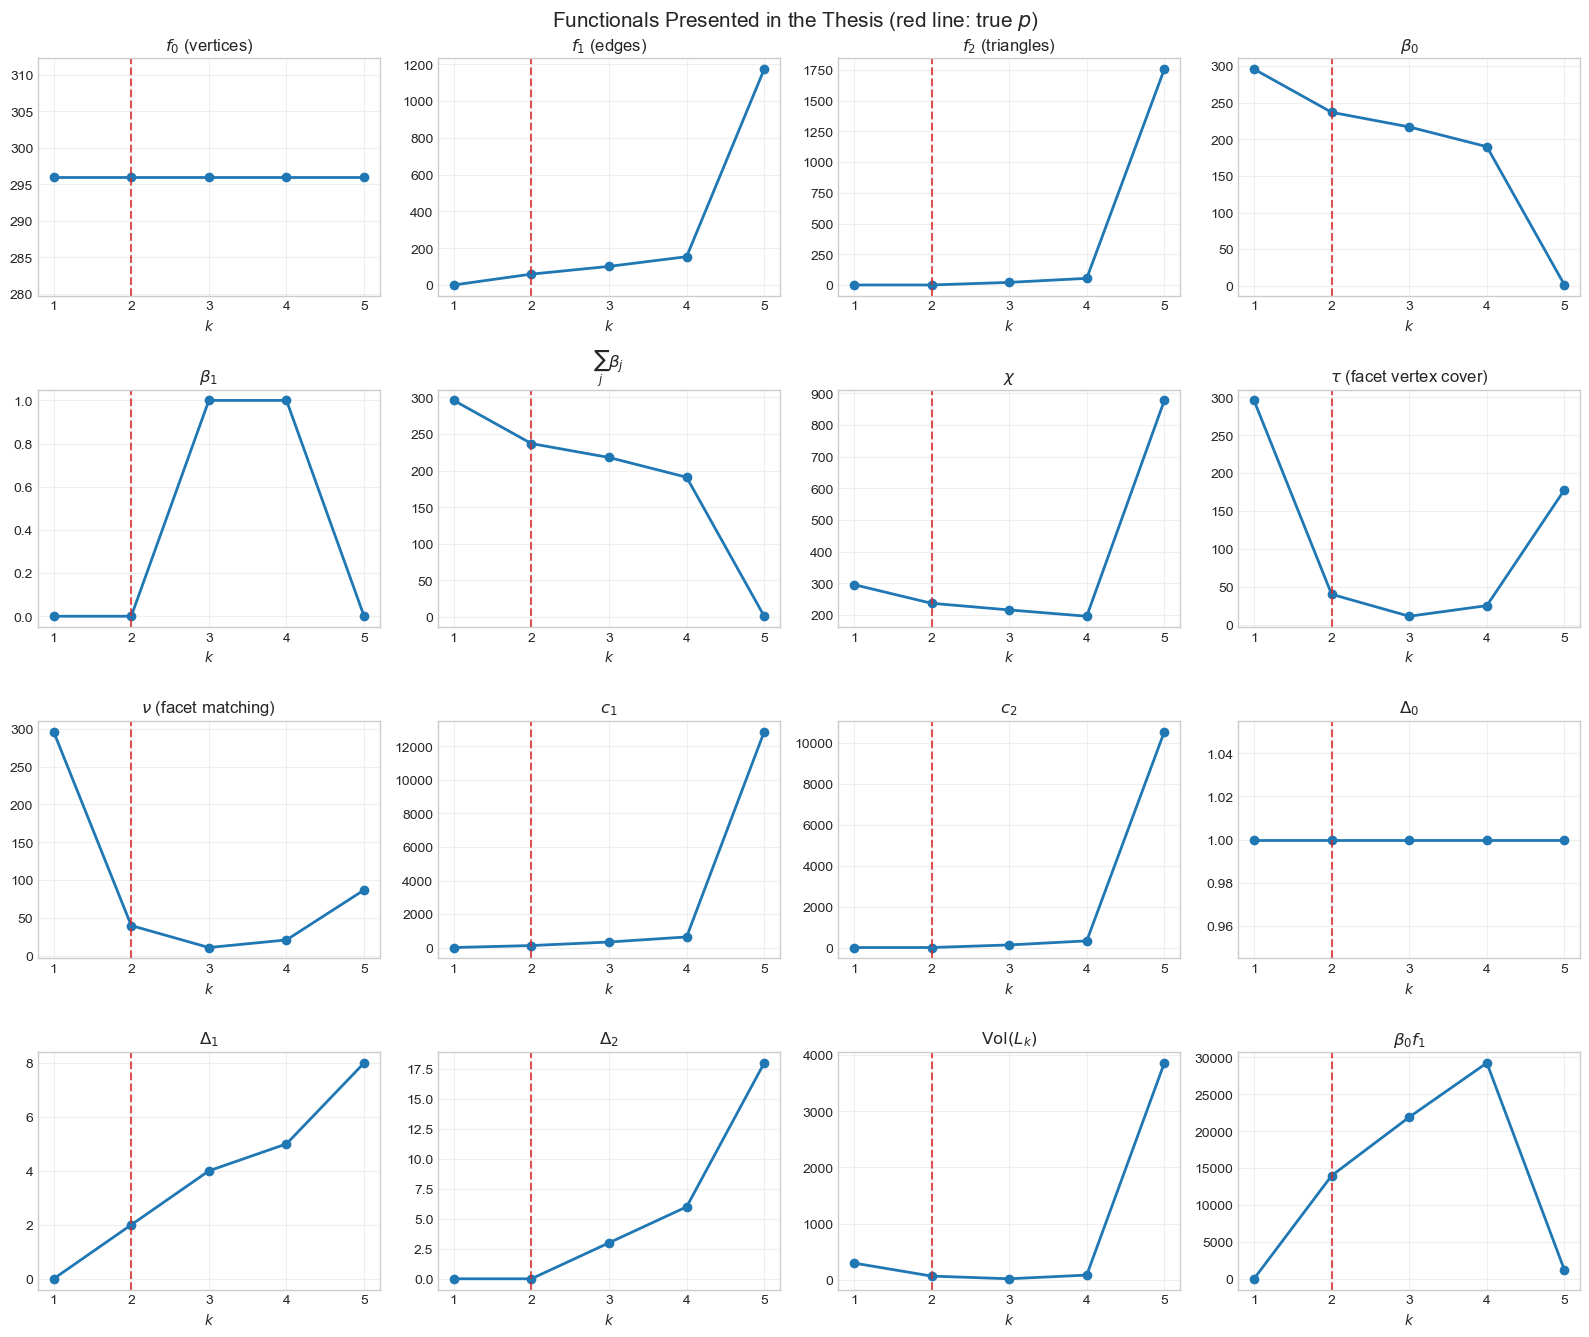

In [69]:
true_p = len(phi)
n_functionals = len(thesis_functionals)
n_columns = 4
n_rows = int(np.ceil(n_functionals / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 3.4 * n_rows), squeeze=False)

for ax, (name, values) in zip(axes.flat, thesis_functionals.items()):
    ax.plot(k_values, values, marker="o", linewidth=2)
    ax.axvline(true_p, color="tab:red", linestyle="--", alpha=0.8)
    ax.set_title(name)
    ax.set_xticks(k_values)
    ax.set_xlabel("$k$")
    ax.grid(alpha=0.3)

for ax in axes.flat[n_functionals:]:
    ax.axis("off")

fig.suptitle("Functionals Presented in the Thesis (red line: true $p$)", fontsize=15)
fig.tight_layout()
plt.show()

### Normalized comparison

Each nonconstant profile is divided by its maximum absolute value. This changes only the plotting scale, not the location of its maxima.

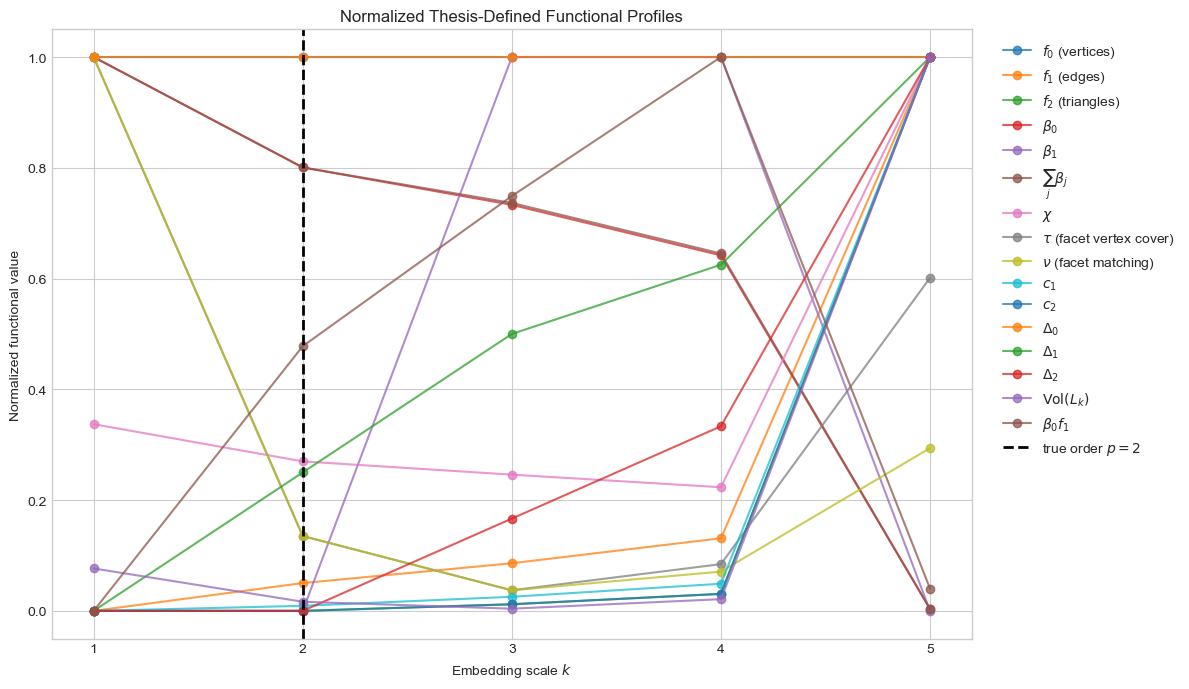

In [70]:
fig, ax = plt.subplots(figsize=(12, 7))
for name, values in thesis_functionals.items():
    scale = np.max(np.abs(values))
    normalized = values / scale if scale > 0 else values
    ax.plot(k_values, normalized, marker="o", alpha=0.75, label=name)

ax.axvline(true_p, color="black", linestyle="--", linewidth=2,
           label=f"true order $p={true_p}$")
ax.set(
    title="Normalized Thesis-Defined Functional Profiles",
    xlabel="Embedding scale $k$",
    ylabel="Normalized functional value",
    xticks=k_values,
)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

## Do any thesis-defined functionals peak at $k=p$?

The next cell reports this directly for the current realization and threshold. A peak in one simulation is evidence, not a consistency result: the profiles depend on the AR coefficients, sample split, random seed, and especially the error threshold $\tau_k$.

In [71]:
peaking_at_p = [
    name for name, values in thesis_functionals.items()
    if np.flatnonzero(values == values.max()).tolist() == [true_p - 1]
]
flat_at_p = [
    name for name, values in thesis_functionals.items()
    if values[true_p - 1] == values.max() and name not in peaking_at_p
]

if peaking_at_p:
    print(f"Thesis-defined functionals with a unique maximum at p={true_p}:")
    for name in peaking_at_p:
        print(" -", name)
else:
    print(f"None of the evaluated thesis-defined functionals has a unique peak at p={true_p}.")

if flat_at_p:
    print("Functionals whose maximum includes p only as part of a plateau:")
    for name in flat_at_p:
        print(" -", name)

None of the evaluated thesis-defined functionals has a unique peak at p=2.
Functionals whose maximum includes p only as part of a plateau:
 - $f_0$ (vertices)
 - $\Delta_0$


## Proposed scale-aware functionals

If the thesis-defined functionals do not isolate $p$, the raw counts are strongly affected by the increasing number of candidate temporal edges as $k$ grows. The following proposals remove that deterministic opportunity effect:

1. **Retained-edge fraction** $f_1(L_k)/|E_k|$.
2. **Connectivity–retention product** $\beta_0(L_k)f_1(L_k)/|E_k|$, a normalized version of the thesis's explicit example $\beta_0f_1$.
3. **Excess retention over the previous scale**, the positive change in retained-edge fraction. This is a transition score on the sequence rather than a functional of one isolated complex.

The second proposal stays closest to the thesis's topological–combinatorial product and is the most natural candidate here.

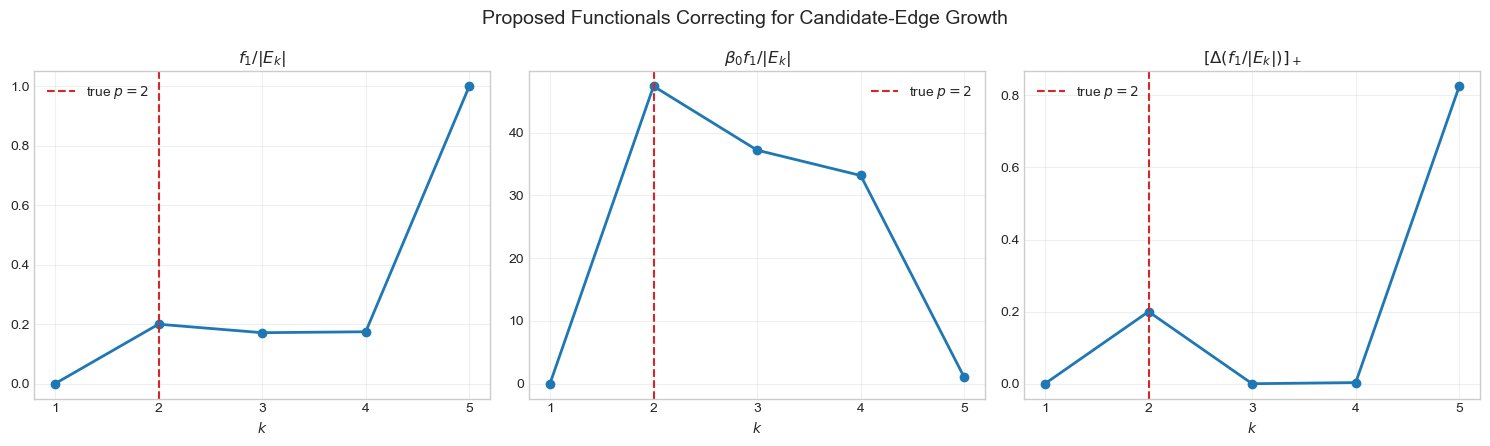

Maximizers of the proposed functionals:
$f_1/|E_k|$                    -> k = [5]
$\beta_0 f_1/|E_k|$            -> k = [2]
$[\Delta(f_1/|E_k|)]_+$        -> k = [5]


In [72]:
f1_values = thesis_functionals[r"$f_1$ (edges)"]
beta0_values = thesis_functionals[r"$\beta_0$"]
edge_fraction = np.divide(
    f1_values,
    candidate_edge_counts,
    out=np.zeros_like(f1_values, dtype=float),
    where=candidate_edge_counts > 0,
)
connectivity_retention = beta0_values * edge_fraction
positive_retention_gain = np.maximum(
    np.diff(edge_fraction, prepend=edge_fraction[0]), 0.0
)

proposed_functionals = {
    r"$f_1/|E_k|$": edge_fraction,
    r"$\beta_0 f_1/|E_k|$": connectivity_retention,
    r"$[\Delta(f_1/|E_k|)]_+$": positive_retention_gain,
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, values) in zip(axes, proposed_functionals.items()):
    ax.plot(k_values, values, marker="o", linewidth=2)
    ax.axvline(true_p, color="tab:red", linestyle="--", label=f"true $p={true_p}$")
    ax.set(title=name, xlabel="$k$", xticks=k_values)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("Proposed Functionals Correcting for Candidate-Edge Growth", fontsize=14)
fig.tight_layout()
plt.show()

print("Maximizers of the proposed functionals:")
for name, values in proposed_functionals.items():
    maximizing_k = k_values[np.flatnonzero(values == values.max())]
    print(f"{name:30s} -> k = {maximizing_k.tolist()}")

# Monte Carlo experiment across different $p$ and $k_{\max}$

The previous section found that

$$f_{\mathrm{CR}}(L_k)=\beta_0(L_k)\frac{f_1(L_k)}{|E_k|}$$

selected the correct order in the single AR(2) realization. Here, this **connectivity–retention functional** is tested across several process orders, ambient dimensions, and independent realizations.

For each simulated series, the complete pipeline is repeated:

1. chronologically split the series into training and test parts;
2. estimate $\hat A_k$ from the training part;
3. calculate test completion errors;
4. construct each similar-error complex $L_k$;
5. evaluate $f_{\mathrm{CR}}(L_k)$; and
6. select the smallest maximizing scale $\hat p$.

The true order is used only to evaluate the selection. The coefficient choices below are all causal/stationary.

In [73]:
# Stable AR coefficient configurations used in the experiment.
experiment_phi = {
    1: [0.65],
    2: [0.75, -0.25],
    3: [0.55, -0.20, 0.12],
    4: [0.50, -0.20, 0.12, -0.08],
}

# For every p, try three different amounts of headroom above the true order.
k_max_offsets = [2, 3, 4]
n_repetitions = 12
experiment_n = 800
experiment_train_fraction = 0.7
experiment_sigma = 0.7
experiment_tau_quantile = 0.5
experiment_seed = 20_260_623


def ar_characteristic_roots(phi):
    """Roots of 1 - phi_1 z - ... - phi_p z^p."""
    phi = np.asarray(phi, dtype=float)
    return np.roots(np.r_[-phi[::-1], 1.0])


for order, coefficients in experiment_phi.items():
    roots = ar_characteristic_roots(coefficients)
    minimum_modulus = np.min(np.abs(roots))
    if minimum_modulus <= 1:
        raise ValueError(f"The AR({order}) coefficients are not causal.")
    print(
        f"AR({order}): phi={coefficients}, "
        f"minimum characteristic-root modulus={minimum_modulus:.3f}"
    )

AR(1): phi=[0.65], minimum characteristic-root modulus=1.538
AR(2): phi=[0.75, -0.25], minimum characteristic-root modulus=2.000
AR(3): phi=[0.55, -0.2, 0.12], minimum characteristic-root modulus=1.757
AR(4): phi=[0.5, -0.2, 0.12, -0.08], minimum characteristic-root modulus=1.826


In [74]:
def connectivity_retention_profile(
    x,
    k_max,
    train_fraction=0.7,
    tau_quantile=0.5,
):
    """Run the train/test complex pipeline and return f_CR(L_k), k=1,...,k_max."""
    split = int(train_fraction * len(x))
    train = x[:split]
    test = x[split:]
    fitted_matrices = fit_completion_matrices(train, k_max)
    n_windows = len(test) - k_max + 1

    scores = np.zeros(k_max, dtype=float)
    beta_0_profile = np.zeros(k_max, dtype=int)
    retained_fraction = np.zeros(k_max, dtype=float)

    for k in range(1, k_max + 1):
        errors = prediction_error_vectors(test, k, k_max, fitted_matrices[k])
        error_norms = np.linalg.norm(errors, axis=1)
        tau_k = float(np.quantile(error_norms, tau_quantile))
        _, retained_edges, beta_0, _ = similar_error_complex(errors, k, tau_k)

        candidate_edges = sum(n_windows - lag for lag in range(1, k))
        edge_fraction = (
            len(retained_edges) / candidate_edges if candidate_edges > 0 else 0.0
        )
        beta_0_profile[k - 1] = beta_0
        retained_fraction[k - 1] = edge_fraction
        scores[k - 1] = beta_0 * edge_fraction

    maximizing_indices = np.flatnonzero(np.isclose(scores, scores.max()))
    selected_k = int(maximizing_indices[0] + 1)
    unique_maximum = len(maximizing_indices) == 1

    return {
        "scores": scores,
        "beta_0": beta_0_profile,
        "edge_fraction": retained_fraction,
        "selected_k": selected_k,
        "unique_maximum": unique_maximum,
    }

## Run the experiment

Increase `n_repetitions` for a more stable study. The default is deliberately moderate so that the notebook remains convenient to rerun.

In [75]:
experiment_rng = np.random.default_rng(experiment_seed)
experiment_results = []

for true_order, coefficients in experiment_phi.items():
    for offset in k_max_offsets:
        experiment_k_max = true_order + offset

        for repetition in range(n_repetitions):
            simulation_seed = int(experiment_rng.integers(0, 2**32 - 1))
            simulated_x = generate_ar_process(
                phi=coefficients,
                n=experiment_n,
                sigma=experiment_sigma,
                intercept=0.0,
                burn_in=500,
                seed=simulation_seed,
            )
            result = connectivity_retention_profile(
                simulated_x,
                k_max=experiment_k_max,
                train_fraction=experiment_train_fraction,
                tau_quantile=experiment_tau_quantile,
            )
            experiment_results.append({
                "p": true_order,
                "k_max": experiment_k_max,
                "offset": offset,
                "repetition": repetition,
                "seed": simulation_seed,
                **result,
            })

print(f"Completed {len(experiment_results)} independent pipeline runs.")

Completed 144 independent pipeline runs.


## Mean functional profiles

The solid line is the mean connectivity–retention score and the shaded band is one standard deviation across simulations.

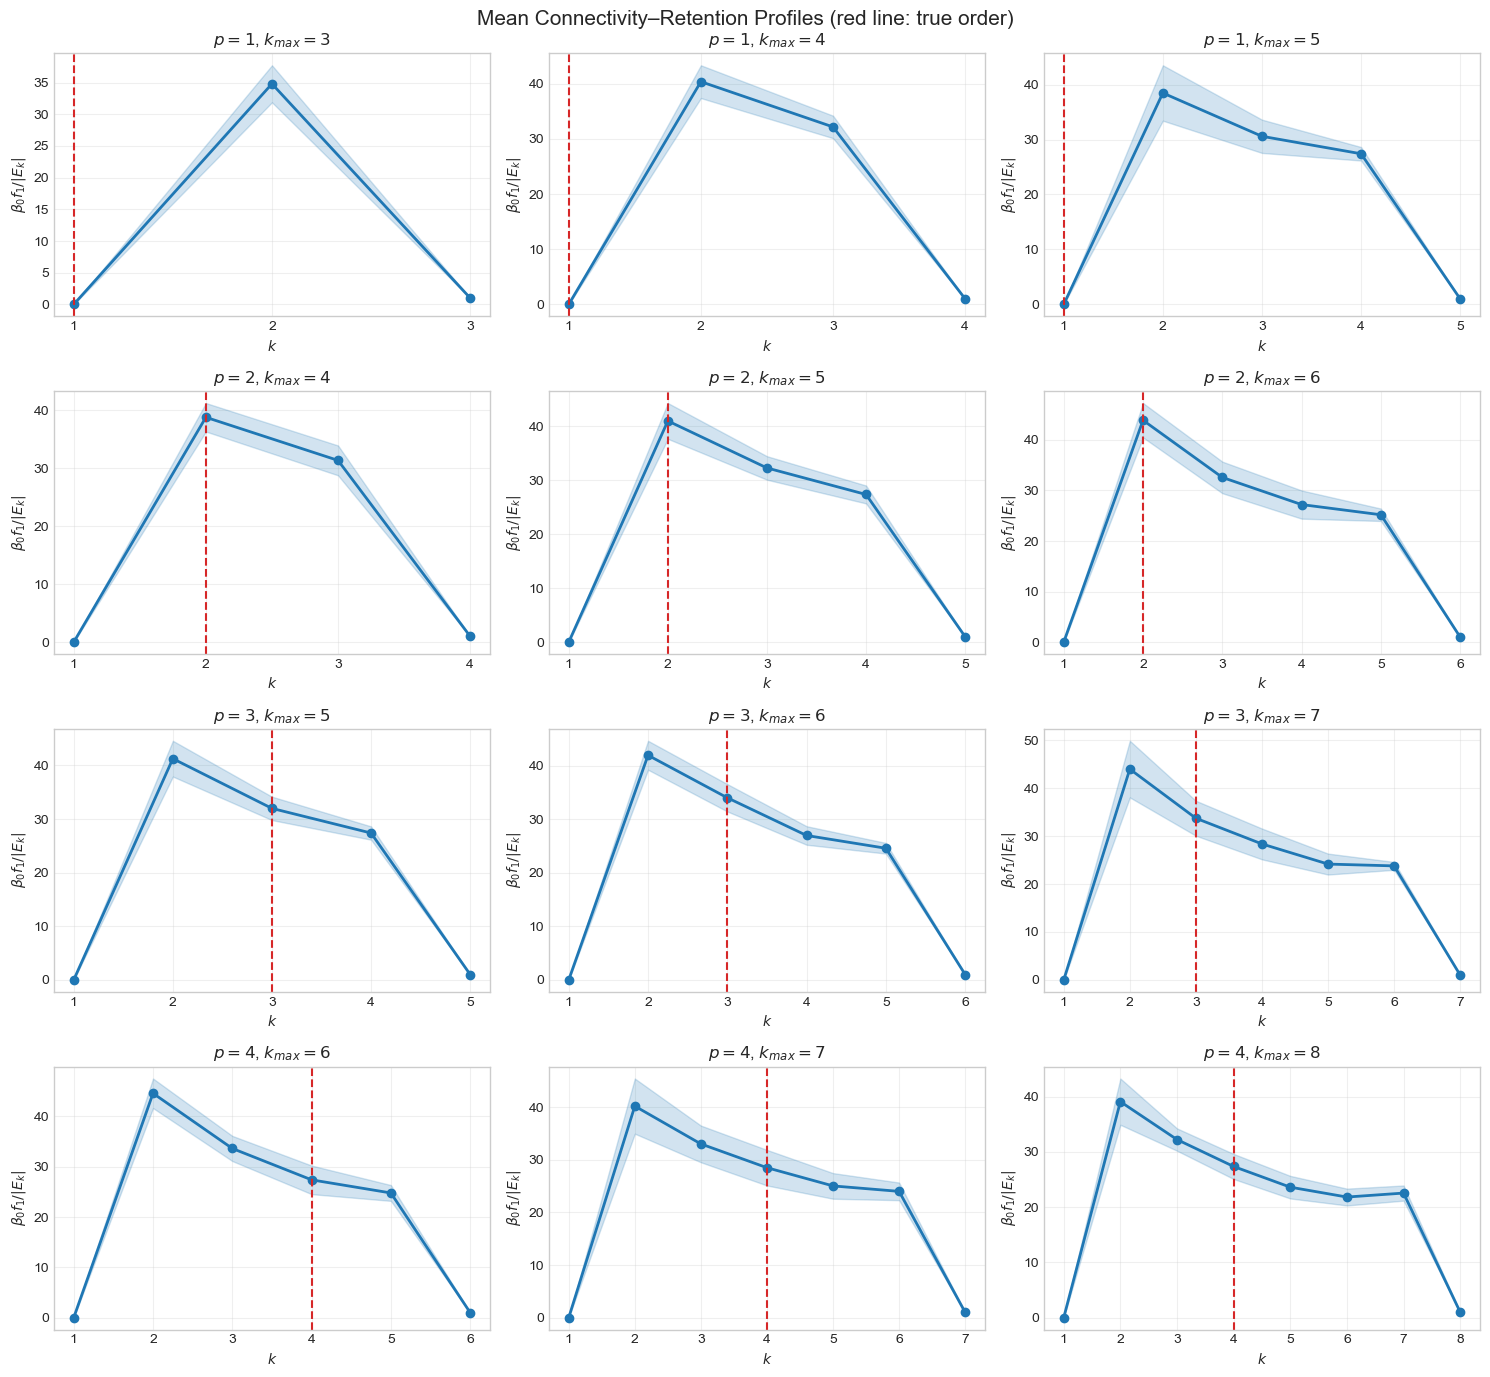

In [76]:
orders = sorted(experiment_phi)
fig, axes = plt.subplots(
    len(orders), len(k_max_offsets),
    figsize=(15, 3.5 * len(orders)),
    squeeze=False,
    sharey=False,
)

for row, true_order in enumerate(orders):
    for column, offset in enumerate(k_max_offsets):
        ax = axes[row, column]
        current_k_max = true_order + offset
        runs = [
            result for result in experiment_results
            if result["p"] == true_order and result["k_max"] == current_k_max
        ]
        score_matrix = np.vstack([result["scores"] for result in runs])
        mean_score = score_matrix.mean(axis=0)
        std_score = score_matrix.std(axis=0, ddof=1)
        scales = np.arange(1, current_k_max + 1)

        ax.plot(scales, mean_score, marker="o", linewidth=2, color="tab:blue")
        ax.fill_between(
            scales,
            np.maximum(mean_score - std_score, 0),
            mean_score + std_score,
            alpha=0.2,
            color="tab:blue",
        )
        ax.axvline(true_order, color="tab:red", linestyle="--", linewidth=1.5)
        ax.set_title(f"$p={true_order}$, $k_{{max}}={current_k_max}$")
        ax.set_xticks(scales)
        ax.set_xlabel("$k$")
        ax.set_ylabel(r"$\beta_0 f_1/|E_k|$")
        ax.grid(alpha=0.3)

fig.suptitle(
    "Mean Connectivity–Retention Profiles (red line: true order)",
    fontsize=15,
)
fig.tight_layout()
plt.show()

## Order-selection accuracy

A run is counted as correct when the smallest maximizing scale of the functional equals the true order. The second heatmap uses the stricter requirement that the maximum at $p$ is unique.

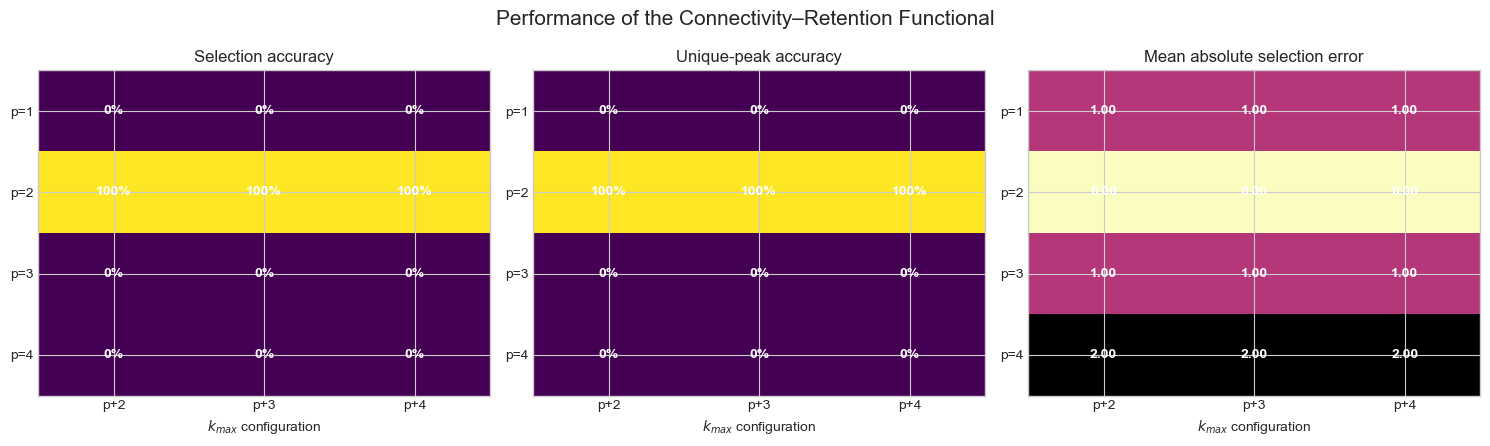

In [77]:
accuracy = np.zeros((len(orders), len(k_max_offsets)))
unique_accuracy = np.zeros_like(accuracy)
mean_absolute_error = np.zeros_like(accuracy)

for row, true_order in enumerate(orders):
    for column, offset in enumerate(k_max_offsets):
        current_k_max = true_order + offset
        runs = [
            result for result in experiment_results
            if result["p"] == true_order and result["k_max"] == current_k_max
        ]
        selections = np.array([result["selected_k"] for result in runs])
        unique = np.array([result["unique_maximum"] for result in runs])
        accuracy[row, column] = np.mean(selections == true_order)
        unique_accuracy[row, column] = np.mean((selections == true_order) & unique)
        mean_absolute_error[row, column] = np.mean(np.abs(selections - true_order))


def annotated_heatmap(ax, values, title, value_format=".0%", cmap="viridis"):
    image = ax.imshow(values, vmin=0, vmax=1 if "%" in value_format else None,
                      cmap=cmap, aspect="auto")
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            ax.text(column, row, format(values[row, column], value_format),
                    ha="center", va="center", color="white", fontweight="bold")
    ax.set_title(title)
    ax.set_xticks(range(len(k_max_offsets)), [f"p+{offset}" for offset in k_max_offsets])
    ax.set_yticks(range(len(orders)), [f"p={order}" for order in orders])
    ax.set_xlabel("$k_{max}$ configuration")
    return image


fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
annotated_heatmap(axes[0], accuracy, "Selection accuracy")
annotated_heatmap(axes[1], unique_accuracy, "Unique-peak accuracy")

mae_image = axes[2].imshow(mean_absolute_error, cmap="magma_r", aspect="auto")
for row in range(mean_absolute_error.shape[0]):
    for column in range(mean_absolute_error.shape[1]):
        axes[2].text(column, row, f"{mean_absolute_error[row, column]:.2f}",
                     ha="center", va="center", color="white", fontweight="bold")
axes[2].set_title("Mean absolute selection error")
axes[2].set_xticks(range(len(k_max_offsets)), [f"p+{offset}" for offset in k_max_offsets])
axes[2].set_yticks(range(len(orders)), [f"p={order}" for order in orders])
axes[2].set_xlabel("$k_{max}$ configuration")

fig.suptitle("Performance of the Connectivity–Retention Functional", fontsize=15)
fig.tight_layout()
plt.show()

## Distribution of selected scales

This heatmap exposes systematic under- or over-estimation that a single accuracy number can hide.

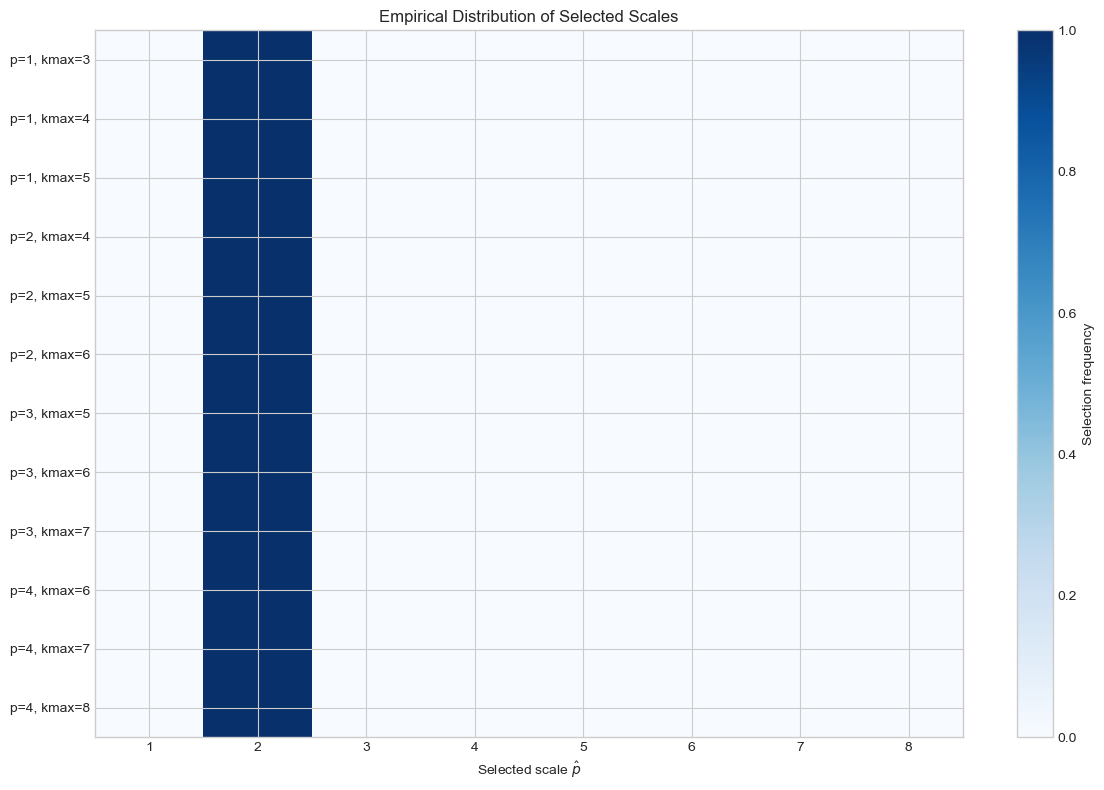

In [78]:
configuration_labels = []
selection_distributions = []
largest_k_max = max(order + offset for order in orders for offset in k_max_offsets)

for true_order in orders:
    for offset in k_max_offsets:
        current_k_max = true_order + offset
        runs = [
            result for result in experiment_results
            if result["p"] == true_order and result["k_max"] == current_k_max
        ]
        selections = np.array([result["selected_k"] for result in runs])
        frequencies = np.array([
            np.mean(selections == scale) for scale in range(1, largest_k_max + 1)
        ])
        configuration_labels.append(f"p={true_order}, kmax={current_k_max}")
        selection_distributions.append(frequencies)

selection_distributions = np.vstack(selection_distributions)

fig, ax = plt.subplots(figsize=(12, 8))
image = ax.imshow(selection_distributions, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(largest_k_max), range(1, largest_k_max + 1))
ax.set_yticks(range(len(configuration_labels)), configuration_labels)
ax.set_xlabel(r"Selected scale $\hat p$")
ax.set_title("Empirical Distribution of Selected Scales")
fig.colorbar(image, ax=ax, label="Selection frequency")
fig.tight_layout()
plt.show()

## Numerical summary

In [79]:
print("Connectivity–retention order-selection summary")
print("=" * 56)
for row, true_order in enumerate(orders):
    for column, offset in enumerate(k_max_offsets):
        current_k_max = true_order + offset
        print(
            f"p={true_order}, k_max={current_k_max}: "
            f"accuracy={accuracy[row, column]:.1%}, "
            f"unique-peak accuracy={unique_accuracy[row, column]:.1%}, "
            f"MAE={mean_absolute_error[row, column]:.2f}"
        )

overall_accuracy = accuracy.mean()
overall_unique_accuracy = unique_accuracy.mean()
print("-" * 56)
print(f"Mean configuration accuracy: {overall_accuracy:.1%}")
print(f"Mean unique-peak accuracy: {overall_unique_accuracy:.1%}")

Connectivity–retention order-selection summary
p=1, k_max=3: accuracy=0.0%, unique-peak accuracy=0.0%, MAE=1.00
p=1, k_max=4: accuracy=0.0%, unique-peak accuracy=0.0%, MAE=1.00
p=1, k_max=5: accuracy=0.0%, unique-peak accuracy=0.0%, MAE=1.00
p=2, k_max=4: accuracy=100.0%, unique-peak accuracy=100.0%, MAE=0.00
p=2, k_max=5: accuracy=100.0%, unique-peak accuracy=100.0%, MAE=0.00
p=2, k_max=6: accuracy=100.0%, unique-peak accuracy=100.0%, MAE=0.00
p=3, k_max=5: accuracy=0.0%, unique-peak accuracy=0.0%, MAE=1.00
p=3, k_max=6: accuracy=0.0%, unique-peak accuracy=0.0%, MAE=1.00
p=3, k_max=7: accuracy=0.0%, unique-peak accuracy=0.0%, MAE=1.00
p=4, k_max=6: accuracy=0.0%, unique-peak accuracy=0.0%, MAE=2.00
p=4, k_max=7: accuracy=0.0%, unique-peak accuracy=0.0%, MAE=2.00
p=4, k_max=8: accuracy=0.0%, unique-peak accuracy=0.0%, MAE=2.00
--------------------------------------------------------
Mean configuration accuracy: 25.0%
Mean unique-peak accuracy: 25.0%


## Interpretation of the experiment

This experiment reveals that the apparent AR(2) success is structural rather than a general order-selection result:

- $L_1$ has no candidate edges by definition, so $f_{\mathrm{CR}}(L_1)=0$. The functional therefore cannot select an AR(1) model.
- As $k$ increases beyond two, the retained-edge fraction may grow, but $\beta_0(L_k)$ generally decreases because more temporal connections merge components.
- Their product consequently tends to favor the first nontrivial temporal graph, namely $k=2$.

Thus, $\beta_0f_1/|E_k|$ is useful as a connectivity–sparsity balance, but the present simulations do **not** support it as a general estimator of the autoregressive order. Its peak at $p=2$ in the original example was a special alignment with this built-in preference.

In [80]:
print("Most frequently selected scale by configuration")
print("=" * 52)
for true_order in orders:
    for offset in k_max_offsets:
        current_k_max = true_order + offset
        selections = np.array([
            result["selected_k"] for result in experiment_results
            if result["p"] == true_order and result["k_max"] == current_k_max
        ])
        values, counts = np.unique(selections, return_counts=True)
        modal_scale = int(values[np.argmax(counts)])
        modal_frequency = counts.max() / len(selections)
        print(
            f"p={true_order}, k_max={current_k_max}: "
            f"mode(hat p)={modal_scale} ({modal_frequency:.1%} of runs)"
        )

Most frequently selected scale by configuration
p=1, k_max=3: mode(hat p)=2 (100.0% of runs)
p=1, k_max=4: mode(hat p)=2 (100.0% of runs)
p=1, k_max=5: mode(hat p)=2 (100.0% of runs)
p=2, k_max=4: mode(hat p)=2 (100.0% of runs)
p=2, k_max=5: mode(hat p)=2 (100.0% of runs)
p=2, k_max=6: mode(hat p)=2 (100.0% of runs)
p=3, k_max=5: mode(hat p)=2 (100.0% of runs)
p=3, k_max=6: mode(hat p)=2 (100.0% of runs)
p=3, k_max=7: mode(hat p)=2 (100.0% of runs)
p=4, k_max=6: mode(hat p)=2 (100.0% of runs)
p=4, k_max=7: mode(hat p)=2 (100.0% of runs)
p=4, k_max=8: mode(hat p)=2 (100.0% of runs)
